# Step 4 -- synthetic spectrum generator, end to end

Goal: validate `io.make_synthetic`, closing the full loop
profile -> synthetic spectrum -> measured EW, both without noise
(against the closed-form formula) and with noise (checking the
*predicted* EW uncertainty against the *actual* scatter from many
noisy realizations -- i.e. is `measure_ew`'s error propagation
correctly calibrated, not just structurally plausible).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import constants as const

from spectral_diag.core import Line, Absorber
from spectral_diag.io import make_synthetic
from spectral_diag.ew import measure_ew
from spectral_diag.profiles import TAU0_CONST

C_KMS = const.c * 1e-3
line = Line(species="Test", wave_rest=1550.0, f=0.1, gamma=2.65e8)
wave = np.linspace(1500, 1600, 200_000)

## Test 1 -- noise-free synthetic spectrum vs. the analytic EW formula

`snr=None` should give a spectrum with `error=0` everywhere, and its
measured EW should match the closed-form linear-regime formula, same
as notebook 03 -- but now going through the full `Spectrum` object
instead of a hand-built flux array.

In [2]:
logN = 11.0
N = 10**logN
absorber = Absorber(species="Test", z=0.0, logN=logN, b=10.0, lines=[line])

spec = make_synthetic(wave, [absorber])
print("error is all zero (noise-free):", np.all(spec.error == 0))

W, _ = measure_ew(spec.wave, spec.flux, spec.continuum)
W_analytic = TAU0_CONST * np.sqrt(np.pi) * N * line.f * line.wave_rest**2 / C_KMS

rel_diff = abs(W - W_analytic) / W_analytic
print(f"W from synthetic spectrum = {W:.6e}")
print(f"W analytic                = {W_analytic:.6e}")
print(f"relative difference = {rel_diff:.4%}")
assert rel_diff < 0.01
print("PASS: make_synthetic + measure_ew reproduces the closed-form EW.")

error is all zero (noise-free): True
W from synthetic spectrum = 2.125146e-04
W analytic                = 2.126890e-04
relative difference = 0.0820%
PASS: make_synthetic + measure_ew reproduces the closed-form EW.


## Test 2 -- are the EW error bars correctly calibrated?

Inject the same (moderate-strength) line many times with independent
noise at a fixed S/N, measure W each time, and compare:
- the *mean predicted* uncertainty from `measure_ew`'s error
  propagation, to
- the *actual* standard deviation of the measured W across
  realizations.

If error propagation is implemented correctly, these two numbers
should agree -- this is a much stronger test than just checking the
code runs without errors.

mean predicted W_err      = 7.454492e-03
actual std of measured W  = 7.640329e-03
ratio (should be close to 1) = 1.025


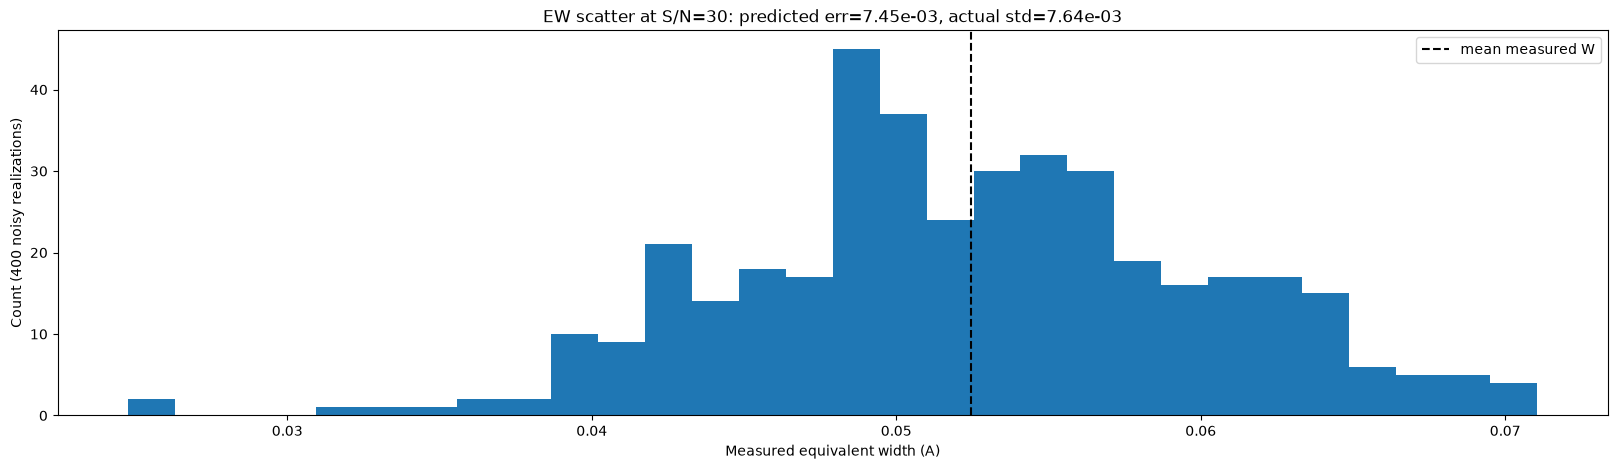

PASS: EW error propagation is correctly calibrated against injected noise.


In [4]:
logN2 = 13.5
absorber2 = Absorber(species="Test", z=0.0, logN=logN2, b=10.0, lines=[line])
wave2 = np.linspace(1545, 1555, 2000)
snr = 30.0

rng = np.random.default_rng(0)
Ws, W_errs = [], []
for _ in range(400):
    spec2 = make_synthetic(wave2, [absorber2], snr=snr, rng=rng)
    W2, W2_err = measure_ew(spec2.wave, spec2.flux, spec2.continuum, error=spec2.error)
    Ws.append(W2)
    W_errs.append(W2_err)

Ws = np.array(Ws)
W_errs = np.array(W_errs)

mean_predicted_err = W_errs.mean()
actual_scatter = Ws.std()
print(f"mean predicted W_err      = {mean_predicted_err:.6e}")
print(f"actual std of measured W  = {actual_scatter:.6e}")
print(f"ratio (should be close to 1) = {actual_scatter / mean_predicted_err:.3f}")

plt.figure(figsize=(20, 5))
plt.hist(Ws, bins=30)
plt.axvline(Ws.mean(), color="k", linestyle="--", label="mean measured W")
plt.xlabel("Measured equivalent width (A)")
plt.ylabel("Count (400 noisy realizations)")
plt.title(f"EW scatter at S/N={snr:.0f}: predicted err={mean_predicted_err:.2e}, actual std={actual_scatter:.2e}")
plt.legend()
plt.show()

assert 0.7 < actual_scatter / mean_predicted_err < 1.3, \
    "predicted and actual EW uncertainty should roughly agree"
print("PASS: EW error propagation is correctly calibrated against injected noise.")

## Next step

`continuum.py` (so this isn't limited to `continuum=1.0`) and
`cog.py` (turn these measured W's into fitted N, b -- the actual
point of the project), validated across the linear, saturated and
damped regimes per CLAUDE.md.